# Mujassam V5 — candidate A_7B_r16: train, then score on the validation set

**Candidate:** `Qwen/Qwen2.5-Coder-7B-Instruct` + QLoRA r=16, alpha=32 — the V5 data with the V3/V4 adapter settings (the main candidate).

V5 trains **from the base model** on ~70 part types (the rest are held out), 12+ phrasings each, every target verified on CPU, with the real retriever in the training prompts. This notebook trains the candidate and scores it on the **validation set only** (2 part types never trained + new requests of trained types + dev p05-p20). **No test set is run here**: the tests run once, on the winning candidate, in `Mujassam_V5_final_test.ipynb`. The winner is chosen by the rule in `docs/v5_plan.md` (addendum 1).

| Step | Time on A100 40 GB |
|---|---|
| Train (2 epochs; checkpoint after each epoch) | ~2 h |
| Validation (epoch 2 and epoch 1 checkpoints) | ~35 min |

**Run:** Runtime → Change runtime type → **A100** → Run all → upload `Mujassam_QWEN7B_V5_project.zip` in cell 2. The model zip downloads automatically after training; the validation zip at the end. Send both back.

In [1]:
# 1. Candidate, GPU and batch profile
CANDIDATE = {"name": "A_7B_r16", "base": "Qwen/Qwen2.5-Coder-7B-Instruct", "r": 16, "alpha": 32}
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader || true
import torch
assert torch.cuda.is_available(), "Choose a GPU runtime: Runtime -> Change runtime type -> A100."
props = torch.cuda.get_device_properties(0)
GPU_NAME, GPU_GB = props.name, props.total_memory / 1024**3
BIG = "14B" in CANDIDATE["base"]
if GPU_GB >= 70:
    BATCH, ACCUM = (4, 4) if BIG else (8, 2)
elif GPU_GB >= 38:
    BATCH, ACCUM = (2, 8) if BIG else (4, 4)
else:
    raise SystemExit("This candidate needs an A100 (40/80 GB) or an RTX PRO 6000.")
print(f"{CANDIDATE['name']} on {GPU_NAME} ({GPU_GB:.0f} GB) | batch {BATCH} x {ACCUM} = {BATCH * ACCUM} per step")

NVIDIA A100-SXM4-80GB, 81920 MiB
A_7B_r16 on NVIDIA A100-SXM4-80GB (79 GB) | batch 8 x 2 = 16 per step


In [2]:
# 2. Upload Mujassam_QWEN7B_V5_project.zip
import os, sys, zipfile, shutil, json, hashlib, glob, time, math
from pathlib import Path
from collections import Counter
from google.colab import files

PROJECT = Path("/content/mujassam_mvp_project")
if PROJECT.exists():
    shutil.rmtree(PROJECT)
uploaded = files.upload()
with zipfile.ZipFile(next(iter(uploaded))) as z:
    z.extractall("/content")
os.chdir(PROJECT)
sys.path.insert(0, str(PROJECT))
print("Working directory:", os.getcwd())

# Google Drive keeps the model, the epoch checkpoints and the scores if Colab disconnects.
# Click "Allow" in the pop-up. If you cancel, everything still downloads as before.
DRIVE = None
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE = Path("/content/drive/MyDrive/mujassam_v5")
    DRIVE.mkdir(parents=True, exist_ok=True)
    print("Google Drive mounted: results are also saved to", DRIVE)
except Exception as exc:
    print("Google Drive not mounted (results are only downloaded):", exc)

def to_drive(path):
    """Copy a file to Drive if it is mounted; never stops the run."""
    if DRIVE is None:
        return
    try:
        shutil.copy(path, DRIVE / Path(path).name)
        print("saved to Drive:", DRIVE / Path(path).name)
    except Exception as exc:
        print("Drive copy failed:", exc)

Saving Mujassam_QWEN7B_V5_project.zip to Mujassam_QWEN7B_V5_project.zip
Working directory: /content/mujassam_mvp_project
Mounted at /content/drive
Google Drive mounted: results are also saved to /content/drive/MyDrive/mujassam_v5


In [3]:
# 3. Install (CadQuery 2.8 as in every earlier run), then the CPU smoke test of the geometry half
!apt-get -qq install -y libgl1 libxrender1 libglu1-mesa > /dev/null 2>&1
!pip install -q "cadquery==2.8.0" "trimesh>=4.0" 2>&1 | tail -1
!pip install -q "transformers>=4.46" "accelerate>=1.0" "bitsandbytes>=0.44" "peft>=0.13" "trl>=0.12" "datasets>=3.0" "sentence-transformers>=3.0" "chromadb>=0.5" "gradio==6.29.0" 2>&1 | tail -1
!pip uninstall -y -q torchao   # Colab's torchao 0.10 breaks newer peft adapter loading; not used here
!python scripts/smoke_test.py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 5.1 MB/s eta 0:00:00
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.1 which is incompatible.
Smoke test passed. Gates hit: ['code', 'intent', 'pass']. STL: /content/mujassam_mvp_project/out/smoke/r3.stl
Scale guard passed: 100.0x -> /content/mujassam_mvp_project/out/scale_smoke/r1_scaled.step
Single-solid gate passed: ['geometry', 'pass'], faces=8


In [4]:
# 4. Record the exact library versions of this session
import importlib.metadata as md
VERSIONS = {}
for p in ["torch", "transformers", "peft", "bitsandbytes", "accelerate", "datasets", "trl",
          "sentence-transformers", "chromadb", "cadquery", "trimesh", "gradio"]:
    try:
        VERSIONS[p] = md.version(p)
    except md.PackageNotFoundError:
        VERSIONS[p] = None
Path("out").mkdir(exist_ok=True)
Path("out/environment_versions.json").write_text(json.dumps({"gpu": GPU_NAME, **VERSIONS}, indent=2))
!pip freeze > out/environment_freeze.txt
print(json.dumps(VERSIONS, indent=1))

{
 "torch": "2.11.0+cu130",
 "transformers": "5.18.0",
 "peft": "0.21.1",
 "bitsandbytes": "0.50.2",
 "accelerate": "1.15.0",
 "datasets": "4.8.5",
 "trl": "1.15.0",
 "sentence-transformers": "5.7.0",
 "chromadb": "1.5.9",
 "cadquery": "2.8.0",
 "trimesh": "5.1.1",
 "gradio": "6.29.0"
}


In [5]:
# 5. The V5 training conversations (hash-checked against the verified build)
manifest = json.loads(Path("data/v5/manifest.json").read_text())
raw = Path("data/v5/train.jsonl").read_bytes()
assert hashlib.sha256(raw).hexdigest() == manifest["sha256"]["train.jsonl"], "data/v5/train.jsonl is not the verified build"
records = [json.loads(l) for l in raw.decode("utf-8").splitlines() if l.strip()]
print(f"{len(records)} conversations | {Counter(r['kind'] for r in records)} | {len({r['type'] for r in records})} part types")
print("Held out for the test:", manifest["heldout_types"], "| held out for validation:", manifest["val_types"])

6823 conversations | Counter({'direct': 5860, 'repair': 963}) | 76 part types
Held out for the test: ['tube_reducer', 'battery_holder', 'corner_brace_plate', 'bolt_circle_flange_hub', 'angled_sensor_mount', 'ring_radial_holes', 'd_shaft_hub'] | held out for validation: ['pull_handle', 'screw_cap']


In [6]:
# 6. Base model in 4-bit + a FRESH LoRA adapter for this candidate
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from mujassam.runtime_v3 import compute_dtype

BASE_MODEL = CANDIDATE["base"]
DTYPE = compute_dtype()
tok = AutoTokenizer.from_pretrained(BASE_MODEL, use_fast=True)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "right"
quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                           bnb_4bit_compute_dtype=DTYPE, bnb_4bit_use_double_quant=True)
model = AutoModelForCausalLM.from_pretrained(BASE_MODEL, device_map="auto", quantization_config=quant,
                                             low_cpu_mem_usage=True)
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)
model.config.use_cache = False
LORA = dict(r=CANDIDATE["r"], lora_alpha=CANDIDATE["alpha"], lora_dropout=0.05, bias="none", task_type="CAUSAL_LM",
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"])
model = get_peft_model(model, LoraConfig(**LORA))
model.print_trainable_parameters()

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 40,370,176 || all params: 7,655,986,688 || trainable%: 0.5273


In [7]:
# 7. Assistant-only tokens: the loss is on the CadQuery answer only, never on the prompt
import random, numpy as np
from datasets import Dataset

MAX_TOKENS = 2048

def encode_assistant_only(messages, max_length=MAX_TOKENS):
    full = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=False)
    target = messages[-1]["content"]
    pos = full.rfind(target)
    assert pos >= 0, "assistant target not found in the formatted chat"
    prefix_ids = tok(full[:pos], add_special_tokens=False)["input_ids"]
    full_ids = tok(full, add_special_tokens=False)["input_ids"]
    lcp = 0
    for a, b in zip(prefix_ids, full_ids):
        if a != b:
            break
        lcp += 1
    target_ids = full_ids[lcp:]
    if len(target_ids) >= max_length - 32:
        return None
    keep = max_length - len(target_ids)
    prompt_ids = full_ids[max(0, lcp - keep):lcp]
    ids = prompt_ids + target_ids
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": [-100] * len(prompt_ids) + target_ids,
            "n_target": len(target_ids), "truncated": len(prompt_ids) < lcp}

encoded = [e for e in (encode_assistant_only(r["messages"]) for r in records) if e is not None]
assert len(encoded) >= 0.99 * len(records), "too many conversations exceed the token budget"
lens = [len(e["input_ids"]) for e in encoded]
print(f"encoded {len(encoded)}/{len(records)} | tokens p50/p90/max {int(np.percentile(lens, 50))}/"
      f"{int(np.percentile(lens, 90))}/{max(lens)} | prompt-truncated {sum(e['truncated'] for e in encoded)}")
random.Random(20261012).shuffle(encoded)
n_val = max(32, len(encoded) // 50)                    # 2% in-distribution validation LOSS (curve only)
cols = ("input_ids", "attention_mask", "labels")
val_ds = Dataset.from_list([{k: e[k] for k in cols} for e in encoded[:n_val]])
train_ds = Dataset.from_list([{k: e[k] for k in cols} for e in encoded[n_val:]])
steps = 2 * len(train_ds) // (BATCH * ACCUM)
print(f"train {len(train_ds)} | val {len(val_ds)} | about {steps} optimizer steps over 2 epochs")

encoded 6823/6823 | tokens p50/p90/max 1352/1631/2048 | prompt-truncated 68
train 6687 | val 136 | about 835 optimizer steps over 2 epochs


In [8]:
# 8. Train: 2 epochs, an adapter checkpoint after each epoch (both are scored on validation below)
import inspect
from transformers import Trainer, TrainingArguments

class PadCollator:
    def __init__(self, pad_id):
        self.pad_id = pad_id
    def __call__(self, feats):
        m = max(len(f["input_ids"]) for f in feats)
        pad = lambda seq, v: seq + [v] * (m - len(seq))  # noqa: E731
        return {"input_ids": torch.tensor([pad(f["input_ids"], self.pad_id) for f in feats]),
                "attention_mask": torch.tensor([pad(f["attention_mask"], 0) for f in feats]),
                "labels": torch.tensor([pad(f["labels"], -100) for f in feats])}

TA_PARAMS = inspect.signature(TrainingArguments.__init__).parameters
RUN_DIR = str(DRIVE / CANDIDATE["name"] / "v5_run") if DRIVE else "out/v5_run"   # on Drive: survives a disconnect
ARGS = dict(
    output_dir=RUN_DIR, num_train_epochs=2, per_device_train_batch_size=BATCH,
    gradient_accumulation_steps=ACCUM, per_device_eval_batch_size=BATCH, learning_rate=1e-4,
    lr_scheduler_type="cosine", warmup_steps=max(1, int(0.03 * steps)), weight_decay=0.0, max_grad_norm=0.3,
    logging_steps=10, eval_strategy="steps", eval_steps=100, save_strategy="epoch", save_total_limit=2,
    bf16=DTYPE == torch.bfloat16, fp16=DTYPE == torch.float16,
    gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
    optim="paged_adamw_8bit", report_to="none", remove_unused_columns=False, seed=42,
)
if "group_by_length" in TA_PARAMS:
    ARGS["group_by_length"] = True
elif "train_sampling_strategy" in TA_PARAMS:
    ARGS["train_sampling_strategy"] = "group_by_length"
if "length" not in train_ds.column_names:
    train_ds = train_ds.add_column("length", [len(x) for x in train_ds["input_ids"]])
def make_trainer():
    return Trainer(model=model, args=TrainingArguments(**ARGS), train_dataset=train_ds, eval_dataset=val_ds,
                   data_collator=PadCollator(tok.pad_token_id))

RESUME = bool(glob.glob(f"{RUN_DIR}/checkpoint-*"))
if RESUME:
    print("Resuming from the last saved epoch in", RUN_DIR)
t0 = time.time()
trainer = make_trainer()
try:
    train_result = trainer.train(resume_from_checkpoint=True if RESUME else None)
except torch.cuda.OutOfMemoryError:
    # Safety net: same effective batch with half the sequences per pass, then train again from the start.
    del trainer
    import gc; gc.collect(); torch.cuda.empty_cache()
    BATCH, ACCUM = max(1, BATCH // 2), ACCUM * 2
    ARGS.update(per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH, gradient_accumulation_steps=ACCUM)
    print(f"GPU memory was short: retrying with batch {BATCH} x {ACCUM}")
    trainer = make_trainer()
    train_result = trainer.train(resume_from_checkpoint=True if glob.glob(f"{RUN_DIR}/checkpoint-*") else None)
TRAIN_MINUTES = (time.time() - t0) / 60
print(f"Training done in {TRAIN_MINUTES:.0f} min, {trainer.state.global_step} steps | final train loss "
      f"{train_result.training_loss:.4f}")

Step,Training Loss,Validation Loss
100,0.147270,0.169673
200,0.036029,0.048112
300,0.011174,0.023667
400,0.004149,0.008940
500,0.003242,0.003147
600,0.003084,0.001692
700,0.002675,0.001461
800,0.001836,0.001362
836,0.001628,0.001390


Training done in 128 min, 836 steps | final train loss 0.0646


In [9]:
# 9. Save this candidate's adapter NOW and download it
ADAPTER = Path(f"out/qlora_v5_{CANDIDATE['name']}")
model.save_pretrained(ADAPTER)
tok.save_pretrained(ADAPTER)
(ADAPTER / "v5_training.json").write_text(json.dumps({
    "candidate": CANDIDATE, "epochs": 2, "lr": 1e-4, "batch": BATCH * ACCUM, "max_tokens": MAX_TOKENS,
    "train_minutes": round(TRAIN_MINUTES, 1), "gpu": GPU_NAME, "train_sha256": manifest["sha256"]["train.jsonl"],
    "n_train": len(train_ds), "n_val_loss": len(val_ds), "final_train_loss": train_result.training_loss,
    "log_history": trainer.state.log_history}, indent=1))
ZIP = f"/content/mujassam_v5_{CANDIDATE['name']}_adapter"
shutil.make_archive(ZIP, "zip", ADAPTER)
print("Adapter zip:", round(Path(ZIP + ".zip").stat().st_size / 1e6), "MB")
to_drive(ZIP + ".zip")
files.download(ZIP + ".zip")

Adapter zip: 152 MB
saved to Drive: /content/drive/MyDrive/mujassam_v5/mujassam_v5_A_7B_r16_adapter.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

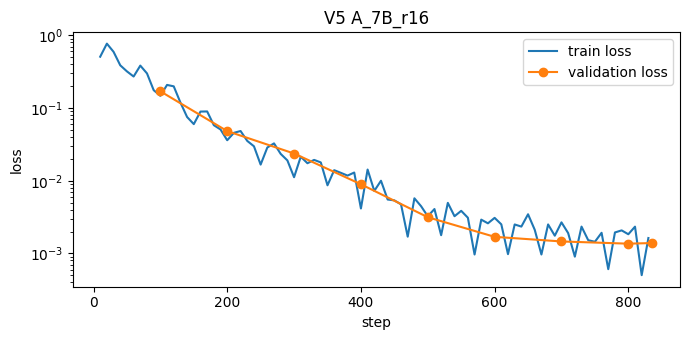

In [10]:
# 10. Loss curves (train vs the 2% in-distribution validation loss)
import matplotlib.pyplot as plt
hist = trainer.state.log_history
tr = [(h["step"], h["loss"]) for h in hist if "loss" in h]
ev = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
plt.figure(figsize=(7, 3.5))
plt.plot(*zip(*tr), label="train loss")
if ev:
    plt.plot(*zip(*ev), "o-", label="validation loss")
plt.xlabel("step"); plt.ylabel("loss"); plt.yscale("log"); plt.legend(); plt.title(f"V5 {CANDIDATE['name']}")
plt.tight_layout(); plt.savefig(f"out/v5_{CANDIDATE['name']}_curve.png", dpi=120); plt.show()

## Validation (model selection only — no test set here)
Both the final adapter (epoch 2) and the epoch-1 checkpoint run the final pipeline (prompt + contracts, RAG, greedy, up to 4 rounds, V3 validator, feature gate) on the validation set: 2 never-trained part types, new requests of trained types, and dev p05-p20.

In [11]:
# Evaluation helpers: locked sets, Wilson intervals, exact McNemar, one evaluate() for every run
from mujassam.runtime_v3 import build_final_pipeline
from mujassam.evaluate import load_prompts, run_generative_eval, report_view, summarise
from mujassam.monitor import RunLog
from mujassam.partgrid import show_parts

def sha(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

LOCKED = json.loads(Path("data/v5/locked_tests.json").read_text())
SETS = {}
for key, info in LOCKED.items():
    assert sha(info["path"]) == info["sha256"], f"{info['path']} changed since it was locked"
    rows = load_prompts(Path(info["path"]))
    if "ids" in info:
        rows = [r for r in rows if r["id"] in info["ids"]]
    assert len(rows) == info["n"], (key, len(rows))
    SETS[key] = rows
SETS["validation"] = SETS["val_v5"] + SETS["dev_p05_p20"]
print({k: len(v) for k, v in SETS.items()})

def wilson(k, n, z=1.96):
    if n == 0:
        return (0.0, 0.0)
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))

def mcnemar(a_ok, b_ok):
    """Exact two-sided McNemar p-value for paired pass/fail lists."""
    b = sum(1 for x, y in zip(a_ok, b_ok) if x and not y)
    c = sum(1 for x, y in zip(a_ok, b_ok) if y and not x)
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(0, min(b, c) + 1)) / 2 ** n)

run_log = RunLog(Path("out/v5_runs.jsonl"), alert_after=10**6)
RESULTS = {}

def evaluate(label, key, pipeline, adapter_off=False):
    tag = f"{label}_{key}".replace(" ", "_")
    if adapter_off:
        with model.disable_adapter():
            run = run_generative_eval(pipeline, SETS[key], tag, run_log=run_log)
    else:
        run = run_generative_eval(pipeline, SETS[key], tag, run_log=run_log)
    rep = report_view(run["records"]) if pipeline.s.n_candidates == 1 else None
    RESULTS[(label, key)] = {"gate": run["records"], "report": rep}
    n = len(run["records"])
    k_gate = sum(r["ok"] for r in run["records"])
    lo, hi = wilson(k_gate, n)
    size = f"size pass {sum(r['ok'] for r in rep)}/{n} | " if rep else ""
    print(f"{label} | {key}: {size}size + requested holes {k_gate}/{n} [{lo:.2f}-{hi:.2f}] | "
          f"first try {sum(r['first_round_ok'] for r in run['records'])}/{n}")
    return run

def split_counts(records, rows):
    by = Counter()
    for rec, row in zip(records, rows):
        s = row.get("split", "dev")
        by[(s, "n")] += 1
        by[(s, "pass")] += int(rec["ok"])
    return {s: f"{by[(s, 'pass')]}/{by[(s, 'n')]}" for s in sorted({k[0] for k in by})}

{'dev_p05_p20': 16, 'user_u01_u30': 30, 'heldout_types': 28, 'val_v5': 42, 'reserve_m01_m20': 20, 'in_family_20': 20, 'in_family_f01_f12': 12, 'original_n01_n20': 20, 'validation': 58}


In [ ]:
# 11. Score epoch 2 (final adapter) and epoch 1 (checkpoint) on the validation set
model.eval()
model.config.use_cache = True
pipe = build_final_pipeline(model, tok, validator="v3", feature_check="gate",
                            model_id=f"{BASE_MODEL}+mujassam-v5-{CANDIDATE['name']}")
VAL_ROWS = SETS["validation"]
SCORES = {}
evaluate(f"{CANDIDATE['name']}_ep2", "validation", pipe)
SCORES["ep2"] = RESULTS[(f"{CANDIDATE['name']}_ep2", "validation")]["gate"]

ckpts = sorted(glob.glob(f"{RUN_DIR}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
if len(ckpts) >= 2:
    try:
        model.load_adapter(ckpts[0], adapter_name="ep1")
        model.set_adapter("ep1")
        evaluate(f"{CANDIDATE['name']}_ep1", "validation", pipe)
        SCORES["ep1"] = RESULTS[(f"{CANDIDATE['name']}_ep1", "validation")]["gate"]
    except Exception as exc:                      # the epoch-2 score above is the candidate's score
        print("Epoch-1 checkpoint not scored:", exc)
    finally:
        model.set_adapter("default")

summary = {"candidate": CANDIDATE, "gpu": GPU_NAME, "train_minutes": round(TRAIN_MINUTES, 1)}
for ep, recs in SCORES.items():
    s = summarise(recs)
    summary[ep] = {"pass": sum(r["ok"] for r in recs), "n": len(recs), "by_split": split_counts(recs, VAL_ROWS),
                   "first_try": sum(r["first_round_ok"] for r in recs),
                   "pass_without_missing_holes": s.get("pass_without_missing_holes")}
BEST_EPOCH = max(SCORES, key=lambda e: (summary[e]["pass"], e == "ep2"))
summary["best_epoch"] = BEST_EPOCH
Path(f"out/v5_{CANDIDATE['name']}_validation.json").write_text(json.dumps(summary, indent=1))
print(json.dumps(summary, indent=1))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

v01  | FAIL | rounds=4 | programs=4 | bbox=None
v02  | FAIL | rounds=4 | programs=4 | bbox=None
v03  | FAIL | rounds=4 | programs=4 | bbox=[114.0, 125.5, 56.5]
v04  | FAIL | rounds=4 | programs=4 | bbox=None


In [ ]:
# 12. Download the validation results (and the epoch-1 adapter only if it scored higher)
if BEST_EPOCH == "ep1":
    ep1_zip = f"/content/mujassam_v5_{CANDIDATE['name']}_ep1_adapter"
    shutil.copytree(ckpts[0], "/content/ep1_adapter", dirs_exist_ok=True)
    shutil.copy(ADAPTER / "v5_training.json", "/content/ep1_adapter/v5_training.json")
    shutil.make_archive(ep1_zip, "zip", "/content/ep1_adapter")
    to_drive(ep1_zip + ".zip")
    files.download(ep1_zip + ".zip")
bundle = Path(f"/content/mujassam_v5_{CANDIDATE['name']}_validation.zip")
keep = sorted({f for pattern in ["out/eval_*validation*.json", f"out/v5_{CANDIDATE['name']}_*", "out/environment_*",
                                   f"{ADAPTER}/v5_training.json"] for f in glob.glob(pattern) if Path(f).is_file()})
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for f in keep:
        z.write(f)
print("Validation bundle:", bundle, round(bundle.stat().st_size / 1e6, 2), "MB | best epoch:", BEST_EPOCH)
to_drive(bundle)
files.download(str(bundle))